In [9]:
# Cell-1
# Roll No: 24B11CS208
# Project: Stock Price Prediction
# Algorithm: Prophet (Time-Series Forecasting)
# yfinance → downloading the dataset
# pandas → data manipulation
# numpy → mathematical calculations
# matplotlib → graphical representation
# Prophet → time-series forecasting
# sklearn → model evaluation

In [10]:
#cell-2
import prophet
print("Prophet installed successfully!")
print("Prophet version:", prophet.__version__)

Prophet installed successfully!
Prophet version: 1.4.0


In [11]:
#cell-3
import sys
print(sys.executable)
print(sys.version)


C:\Users\DELL\AppData\Local\Programs\Python\Python313\python.exe
3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [12]:
#cell-4
!pip install prophet yfinance scikit-learn

In [13]:
#cell-5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from prophet import Prophet
from sklearn.metrics import mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


In [52]:
#cell-6
data = yf.download(
    "TCS.NS",
    start="2020-01-01",
    end="2026-01-01"
)
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2020-01-01,1831.109619,1844.879101,1819.620752,1831.447442,1354908
2020-01-02,1822.704590,1841.542864,1815.566377,1841.542864,2380752
2020-01-03,1859.029175,1877.909726,1828.068667,1828.068667,4655761
2020-01-06,1858.860718,1880.402198,1848.258889,1862.704435,3023209
2020-01-07,1863.421753,1870.855507,1844.794675,1858.902185,2429317


In [15]:
#cell-7
print(data)

Price             Close         High          Low         Open   Volume
Ticker           TCS.NS       TCS.NS       TCS.NS       TCS.NS   TCS.NS
Date                                                                   
2020-01-01  1831.109619  1844.879101  1819.620752  1831.447442  1354908
2020-01-02  1822.704590  1841.542864  1815.566377  1841.542864  2380752
2020-01-03  1859.029175  1877.909726  1828.068667  1828.068667  4655761
2020-01-06  1858.860718  1880.402198  1848.258889  1862.704435  3023209
2020-01-07  1863.421753  1870.855507  1844.794675  1858.902185  2429317
...                 ...          ...          ...          ...      ...
2025-12-24  3198.596191  3206.402441  3176.527032  3184.236815  1367708
2025-12-26  3161.010986  3199.559901  3153.108506  3192.910307  1176664
2025-12-29  3133.544678  3168.720560  3125.256568  3161.010777  2079473
2025-12-30  3129.015381  3148.964397  3121.980157  3132.099247  2807593
2025-12-31  3089.887939  3128.244153  3082.467321  3122.461817  

In [16]:
#cell-8
data.head()

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2020-01-01,1831.109619,1844.879101,1819.620752,1831.447442,1354908
2020-01-02,1822.704590,1841.542864,1815.566377,1841.542864,2380752
2020-01-03,1859.029175,1877.909726,1828.068667,1828.068667,4655761
2020-01-06,1858.860718,1880.402198,1848.258889,1862.704435,3023209
2020-01-07,1863.421753,1870.855507,1844.794675,1858.902185,2429317


In [33]:
#cell-9
data.tail()

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2025-12-24,3198.596191,3206.402441,3176.527032,3184.236815,1367708
2025-12-26,3161.010986,3199.559901,3153.108506,3192.910307,1176664
2025-12-29,3133.544678,3168.720560,3125.256568,3161.010777,2079473
2025-12-30,3129.015381,3148.964397,3121.980157,3132.099247,2807593
2025-12-31,3089.887939,3128.244153,3082.467321,3122.461817,3362634


In [34]:
#cell-10
print("Number of rows:", len(data))
print("Number of columns:", len(data.columns))

Number of rows: 1487
Number of columns: 5


In [56]:
#cell-11
print("Dataset Information:")
data.info()
print("\nNull Values:")
print(data.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 1487 entries, 2020-01-01 to 2025-12-31
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Close, TCS.NS)   1487 non-null   float64
 1   (High, TCS.NS)    1487 non-null   float64
 2   (Low, TCS.NS)     1487 non-null   float64
 3   (Open, TCS.NS)    1487 non-null   float64
 4   (Volume, TCS.NS)  1487 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 69.7 KB

Null Values:
Price   Ticker
Close   TCS.NS    0
High    TCS.NS    0
Low     TCS.NS    0
Open    TCS.NS    0
Volume  TCS.NS    0
dtype: int64


In [53]:
#cell-12
print("Original dataset shape:", data.shape)
close_data = data[["Close"]].copy()
print("Closing price data shape:", close_data.shape)
close_data.head()

Original dataset shape: (1487, 5)
Closing price data shape: (1487, 1)


Price,Close
Ticker,TCS.NS
Date,
2020-01-01,1831.109619
2020-01-02,1822.704590
2020-01-03,1859.029175
2020-01-06,1858.860718
2020-01-07,1863.421753


In [37]:
#cell-13
# Extract TCS closing price
close_data = data["Close"].copy()
# If yfinance returns a DataFrame, select TCS.NS
if isinstance(close_data, pd.DataFrame):
    close_data = close_data["TCS.NS"]
# Convert Date from index into a column
prophet_data = close_data.reset_index()
# Rename columns for Prophet
prophet_data.columns = ["ds", "y"]
# Display first 5 rows
prophet_data.head()

,ds,y
0,2020-01-01,1831.109619
1,2020-01-02,1822.704590
2,2020-01-03,1859.029175
3,2020-01-06,1858.860718
4,2020-01-07,1863.421753


In [39]:
#cell-14
print("Prophet data shape:", prophet_data.shape)
print("Columns:", prophet_data.columns.tolist())

Prophet data shape: (1487, 2)
Columns: ['ds', 'y']


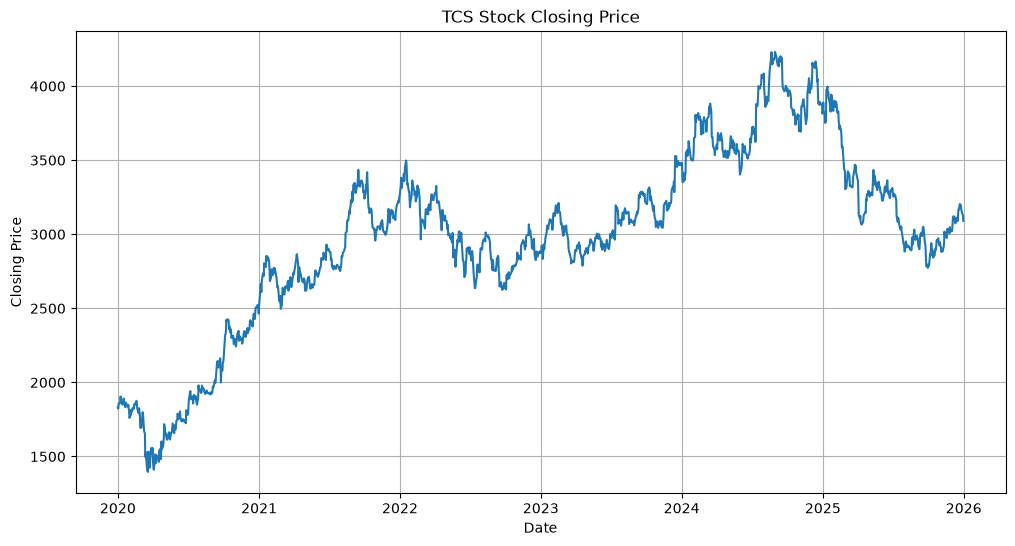

In [38]:
#cell-15
plt.figure(figsize=(12, 6))
plt.plot(prophet_data["ds"], prophet_data["y"])
plt.title("TCS Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.show()

In [40]:
#cell-16
# Calculate 80% training size
train_size = int(len(prophet_data) * 0.8)
# Split the dataset
train_data = prophet_data.iloc[:train_size].copy()
test_data = prophet_data.iloc[train_size:].copy()
# Display sizes
print("Total data:", len(prophet_data))
print("Training data:", len(train_data))
print("Testing data:", len(test_data))
print("\nTraining period:")
print(train_data["ds"].min(), "to", train_data["ds"].max())
print("\nTesting period:")
print(test_data["ds"].min(), "to", test_data["ds"].max())

Total data: 1487
Training data: 1189
Testing data: 298

Training period:
2020-01-01 00:00:00 to 2024-10-18 00:00:00

Testing period:
2024-10-21 00:00:00 to 2025-12-31 00:00:00


In [41]:
#cell-17
# Create Prophet model
model = Prophet()
# Train the model
model.fit(train_data)
print("Prophet model trained successfully!")

14:15:38 - cmdstanpy - INFO - Chain [1] start processing
14:15:38 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully!


In [43]:
#cell-18
# Use test dates for prediction
future = test_data[["ds"]].copy()
# Generate predictions
forecast = model.predict(future)
# Display predictions
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head()

,ds,yhat,yhat_lower,yhat_upper
0,2024-10-21,4087.489090,3953.682183,4216.455984
1,2024-10-22,4087.765172,3965.071023,4209.249573
2,2024-10-23,4087.580434,3958.226712,4222.498125
3,2024-10-24,4085.948226,3965.039456,4207.735770
4,2024-10-25,4084.995829,3954.104740,4210.680125


In [55]:
#cell-19
# Reset indexes
test_data = test_data.reset_index(drop=True)
forecast = forecast.reset_index(drop=True)
# Create prediction results table
result = pd.DataFrame({
    "Date": test_data["ds"],
    "Actual": test_data["y"],
    "Predicted": forecast["yhat"]
})
result.head()

,Date,Actual,Predicted
0,2024-10-21,3799.675049,4087.489090
1,2024-10-22,3739.744141,4087.765172
2,2024-10-23,3787.008789,4087.580434
3,2024-10-24,3769.919189,4085.948226
4,2024-10-25,3778.906738,4084.995829


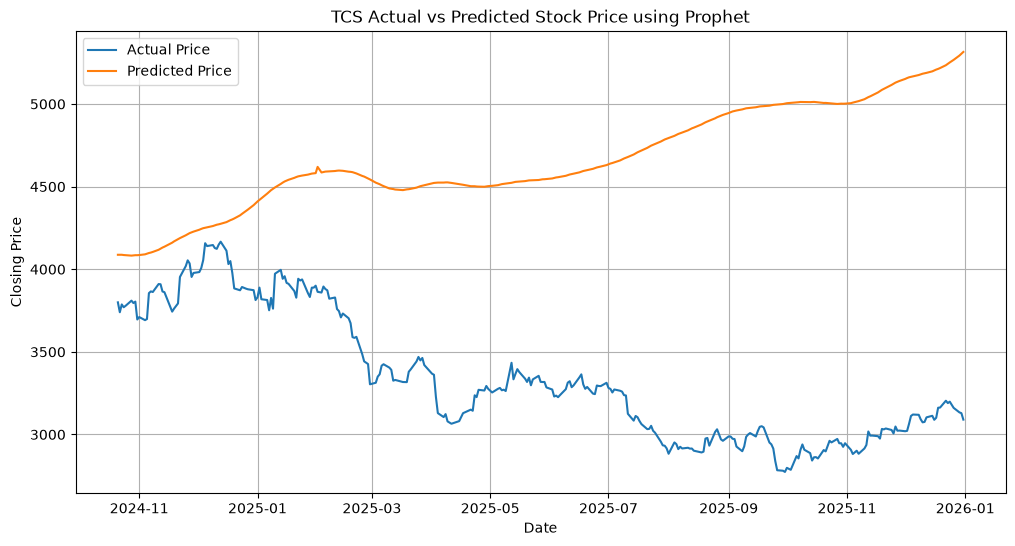

In [48]:
#cell-20
plt.figure(figsize=(12, 6))
# Actual prices
plt.plot(
    test_data["ds"],
    test_data["y"],
    label="Actual Price"
)
# Predicted prices
plt.plot(
    forecast["ds"],
    forecast["yhat"],
    label="Predicted Price"
)
plt.title("TCS Actual vs Predicted Stock Price using Prophet")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.show()

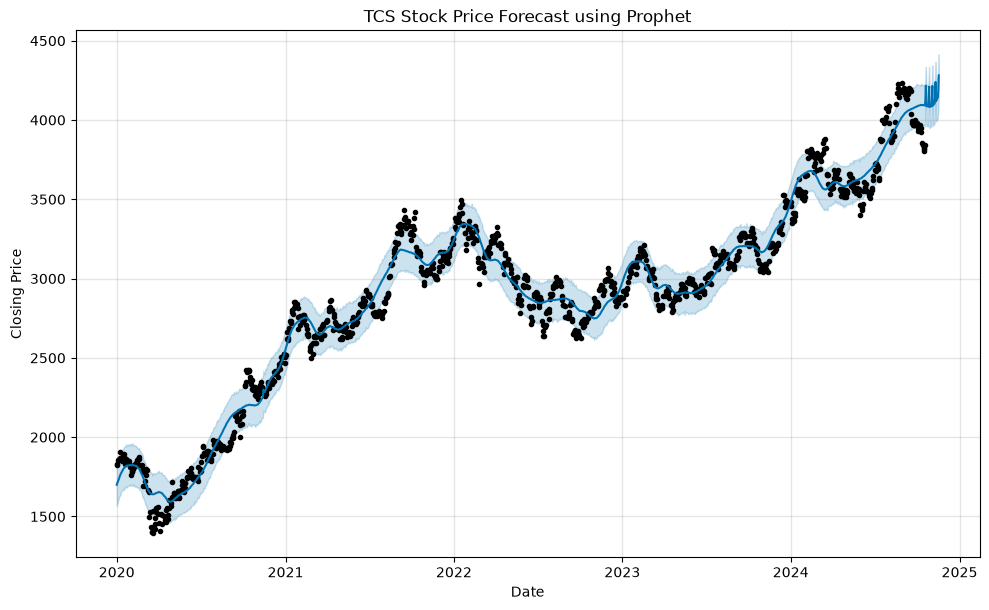

In [49]:
#cell-21
future_dates = model.make_future_dataframe(periods=30)
future_forecast = model.predict(future_dates)
model.plot(future_forecast)
plt.title("TCS Stock Price Forecast using Prophet")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

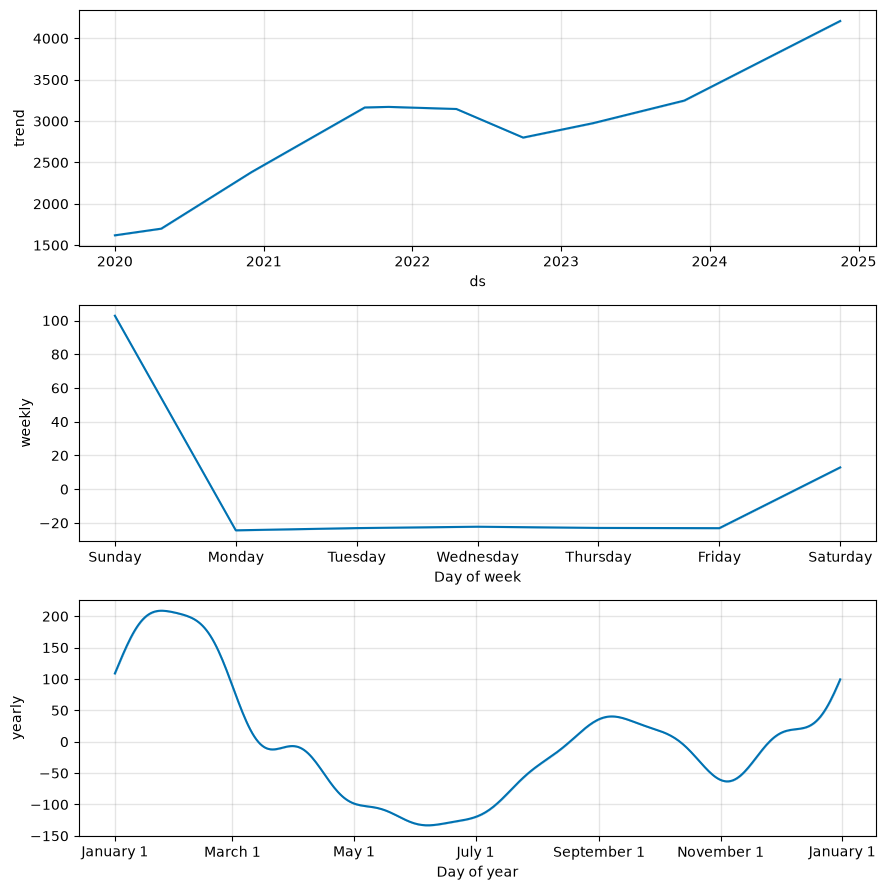

In [50]:
#cell-22
model.plot_components(future_forecast) 
plt.show()

In [51]:
#cell-23
result.to_csv("TCS_Prophet_Predictions.csv", index=False)
print("Prediction results saved successfully!")

Prediction results saved successfully!
